<div style="background: linear-gradient(135deg, #0f172a 0%, #312e81 60%, #4f46e5 100%); padding: 26px; border-radius: 14px; color: #ffffff; font-family: sans-serif; margin-bottom: 16px;">
  <div style="font-size: 13px; letter-spacing: 1.5px; text-transform: uppercase; color: #a5b4fc; font-weight: bold;">Qiskit Fall Fest &bull; Beginner Lab Tutorial</div>
  <h1 style="margin: 8px 0 10px 0; font-size: 28px; color: #ffffff;">Quantum Random Number Generation</h1>

---


  <p style="margin: 0; font-size: 15px; color: #e0e7ff; line-height: 1.5;">
    Adapted from the Quantum Computing Interest Group materials.
  </p>
</div>

## 0: Install Qiskit & Check Package Versions

---


Run the cell below to install the **Qiskit**, **Qiskit Aer**, and **Matplotlib** libraries in your Colab notebook.

In [ ]:
!pip install -q qiskit qiskit-aer matplotlib pylatexenc

import qiskit
import qiskit_aer

{"qiskit": qiskit.__version__, "qiskit-aer": qiskit_aer.__version__,}

{'qiskit': '2.6.2', 'qiskit-aer': '0.18.4'}

## 1. Classical Coin Flips vs. True Randomness

---



One important application of quantum computers is the generation of random numbers. This can be as simple as a **coin flip**.

First, let's see how a standard classical computer flips a coin using Python's built-in `random` module.

In [ ]:
import random

for n in range(5):
    print("Flip: " + str(n + 1))
    if random.random() < 0.5:
        print("HEADS\n")
    else:
        print("TAILS\n")

Flip: 1
TAILS

Flip: 2
HEADS

Flip: 3
HEADS

Flip: 4
HEADS

Flip: 5
HEADS



The code above doesn't use Qiskit—it uses a classical package called `random`.

Classical computers are **deterministic**, meaning they follow exact instructions.

Because of this, classical random generators are actually **pseudorandom number generators (PRNGs)**: they take a starting input (a **seed**) and follow a math formula to produce numbers that *seem* random.

If you knew what was going on under the hood, you could predict every number that comes out!

For example, suppose we measure the exact **system clock time** when a coin flip operation is performed and check whether the very last digit (which changes the fastest) is even or odd:

In [ ]:
import time

for n in range(5):
    t = str(time.time())
    print("Flip " + str(n + 1) + "  (system clock time = " + t + ")")
    if int(t[-1]) % 2 == 0:
        print("HEADS\n")
    else:
        print("TAILS\n")

Flip 1  (system clock time = 1795350653.6997693)
TAILS

Flip 2  (system clock time = 1795350653.6998696)
HEADS

Flip 3  (system clock time = 1795350653.6998868)
HEADS

Flip 4  (system clock time = 1795350653.6999)
TAILS

Flip 5  (system clock time = 1795350653.6999137)
TAILS



This already does a sufficient job at seeming random, but all classical methods have limits.

In important applications, weak randomness causes real problems:
* **Scientific simulations** may produce skewed statistics if the random numbers have hidden patterns.
* **Cryptography and security** can be cracked if encryption keys are created with predictable numbers.

We can solve this using a genuine source of randomness in nature: **measuring a quantum superposition**.

Unlike a pseudorandom generator, a qubit does not store a hidden answer before you measure it—the outcome is undefined until the moment of measurement.

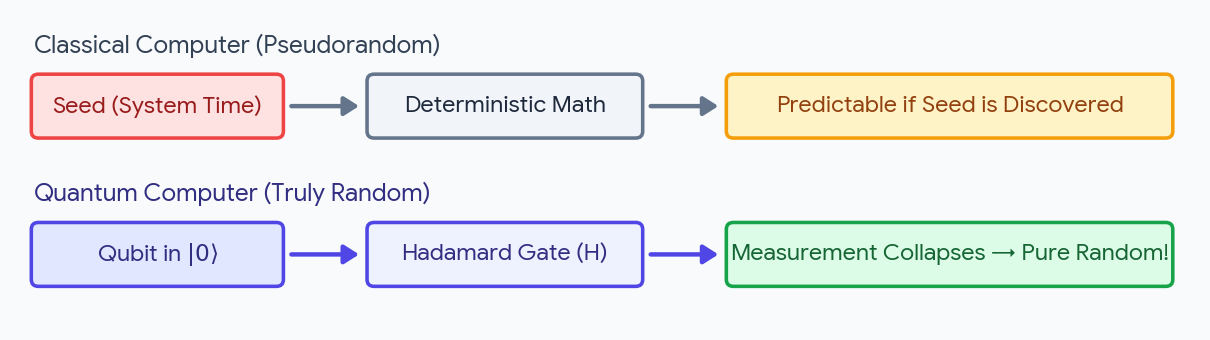

---
## 2. Quantum Coin Flip

To generate a single random bit, we need only **one qubit** (`QuantumRegister(1)`) and **one classical bit** (`ClassicalRegister(1)`) to record the measurement result.

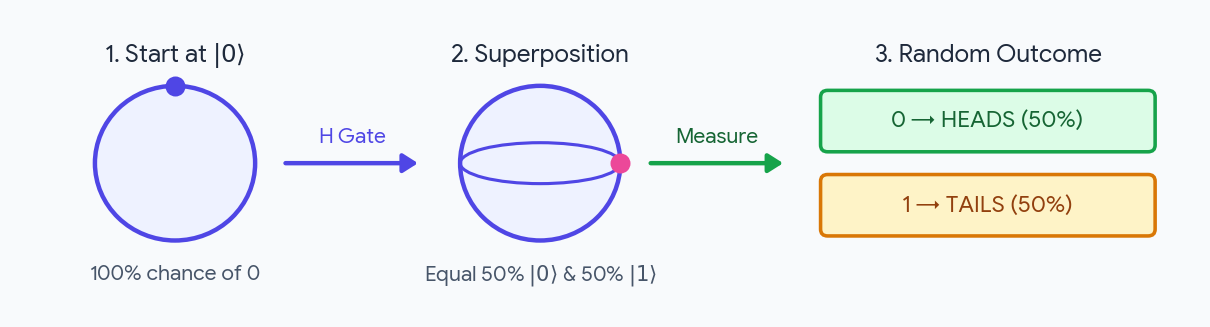

Let's create our quantum register, classical register, and quantum circuit.

In [ ]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit

q = QuantumRegister(1)
c = ClassicalRegister(1)
circ = QuantumCircuit(q, c)

We need an equally weighted superposition of $|0\rangle$ and $|1\rangle$ to get a completely random bit. We do this with the **Hadamard gate (`h`)**, and then **measure** the qubit into the classical register.

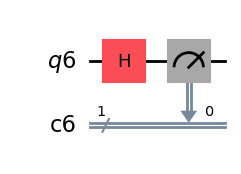

In [ ]:
# Put qubit into equal superposition and measure it
circ.h(q)
circ.measure(q, c)

# Draw the circuit
circ.draw("mpl")

Now that the circuit is complete, let's run it for **5 shots** (5 repeated flips) using Qiskit's `AerSimulator` with `memory=True` so we can inspect every individual coin flip in order.

In [ ]:
from qiskit_aer import AerSimulator

backend = AerSimulator()
job = backend.run(circ, shots=5, memory=True)
data = job.result().get_memory()
print("Raw bit memory:", data)

Raw bit memory: ['0', '0', '0', '1', '0']


For a coin flip, we can simply treat `'0'` as **HEADS** and `'1'` as **TAILS**:

In [ ]:
for output in data:
    print("Flip with output bit value " + output)
    if output == "0":
        print("HEADS\n")
    else:
        print("TAILS\n")

Flip with output bit value 0
HEADS

Flip with output bit value 0
HEADS

Flip with output bit value 0
HEADS

Flip with output bit value 1
TAILS

Flip with output bit value 0
HEADS



> **Important Note — Simulator vs. Real Quantum Processor:**  
> We simulated the qubit on a classical computer above, so those 5 flips were still generated using classical pseudorandomness behind the scenes! To get **true** quantum randomness, you submit this exact same circuit to a real quantum processor (for example, via `QiskitRuntimeService`).  
>  
> However, when you run on real quantum hardware, physical noise typically causes qubits to decay toward the ground state $|0\rangle$, creating a noticeable bias toward `'0'`. We will explore how to simulate and fix that noise in **Section 4**!

---
## 3. More General Probability Distributions

Sometimes we need something more than a single coin flip.

Many applications require generating numbers across a larger range (rather than just $0$ and $1$), or sampling from probability distributions where different outcomes occur with different weights.

### A. Uniform Distribution Over $2^n$ Numbers
To represent numbers larger than $0$ and $1$, we add more qubits. Each extra qubit doubles the number of outcomes, so $n$ qubits produce $2^n$ equally likely binary strings representing integers from **$0$ to $2^n - 1$**.

(We keep $n \le 10$ so the circuit stays manageable and easy to visualize!)

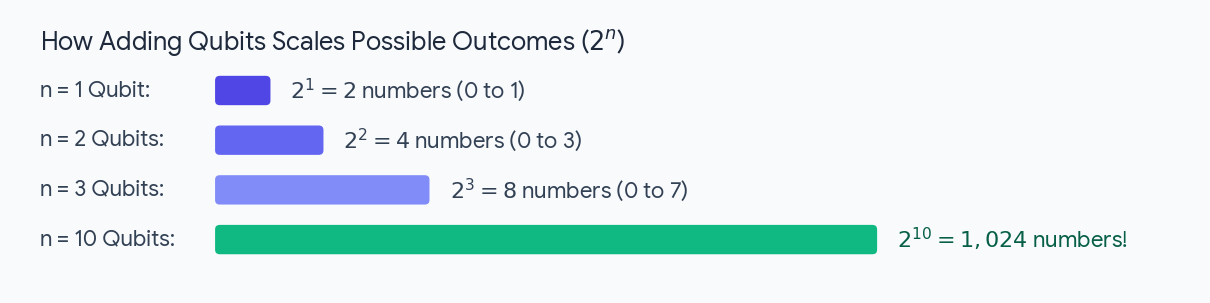

Let's choose $n = 3$ qubits to generate numbers from **$0$ to $7$**, apply a Hadamard gate to each qubit, and run **8,192 shots** to verify that all 8 outcomes are equally likely.

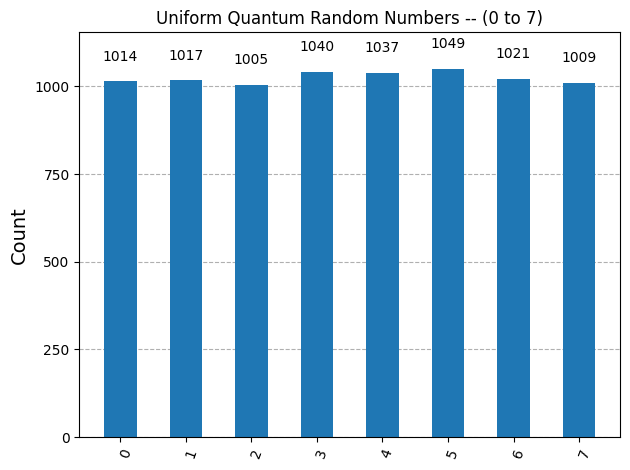

In [ ]:
from qiskit.visualization import plot_histogram

n = 3u
q = QuantumRegister(n)
c = ClassicalRegister(n)
circ = QuantumCircuit(q, c)

for k in range(n):
    circ.h(q[k])

circ.measure(q, c)

job = backend.run(circ, shots=8192)

# Convert binary bitstring counts ('000'..'111') into integer values (0..7) and plot them
bit_counts = job.result().get_counts()
int_counts = {}
for bitstring in bit_counts:
    int_counts[int(bitstring, 2)] = bit_counts[bitstring]

plot_histogram(int_counts, title="Uniform Quantum Random Numbers -- (0 to 7)")

> **1 Shot vs. Many Shots:**  
> Running `shots=8192` shows all 8 equal buckets, proving our qubits were in an equal superposition. When you want **one** random number, you can simply run `shots=1` (or grab a single entry from `get_memory()`).

### B. Custom Non-Uniform Distributions (Biasing Toward Smaller Numbers)
What if you want a **weighted** random number generator—for example, one biased toward smaller numbers?

Instead of a Hadamard gate (which always gives an exact 50/50 split), we can apply an **`rx` rotation gate** to each qubit.

By using a rotation angle that decreases from `q[0]` (the least significant binary digit) to `q[n-1]` (the most significant binary digit), higher qubits stay closer to `0`, naturally skewing the output toward smaller valued integers!

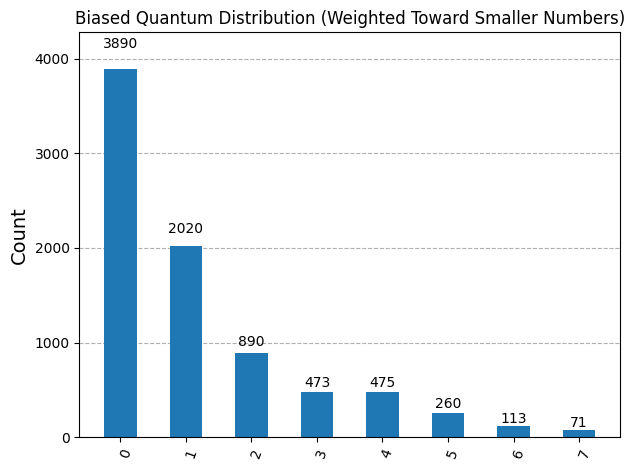

In [ ]:
q = QuantumRegister(n)
c = ClassicalRegister(n)
circ = QuantumCircuit(q, c)

# Apply decreasing rx rotation angles across qubits
for j in range(n):
    circ.rx(3.14159 / (2.5 + j), q[j])

circ.measure(q, c)

job = backend.run(circ, shots=8192)

bit_counts = job.result().get_counts()
int_counts = {}
for bitstring in bit_counts:
    int_counts[int(bitstring, 2)] = bit_counts[bitstring]

plot_histogram(int_counts, title="Biased Quantum Distribution -- (Weighted Toward Smaller Numbers)")

Now let's pull **10 actual random samples** (`shots=10`) from this weighted distribution and convert the binary strings into decimal integers:

In [ ]:
job = backend.run(circ, shots=10, memory=True)
data = job.result().get_memory()
print("Binary samples:", data)

int_data = []
for bitstring in data:
    int_data.append(int(bitstring, 2))
print("Integer samples:", int_data)

Binary samples: ['001', '000', '100', '001', '100', '001', '001', '101', '011', '000']
Integer samples: [1, 0, 4, 1, 4, 1, 1, 5, 3, 0]


---
## 4. Deeper Challenge: Quantum Noise & Error Mitigation

Remember our earlier note about real quantum processors? Even when we build a **uniform** QRNG using Hadamard gates, real quantum hardware is affected by **noise**:
1. **Energy Relaxation ($T_1$ Decay):** Qubits in the excited state $|1\rangle$ can lose energy and relax down to $|0\rangle$ before measurement finishes.
2. **Readout Error:** Measurement sensors occasionally misread a `1` as a `0`.

As a result, **`000` (integer `0`)** and other low-weight bitstrings appear too often!

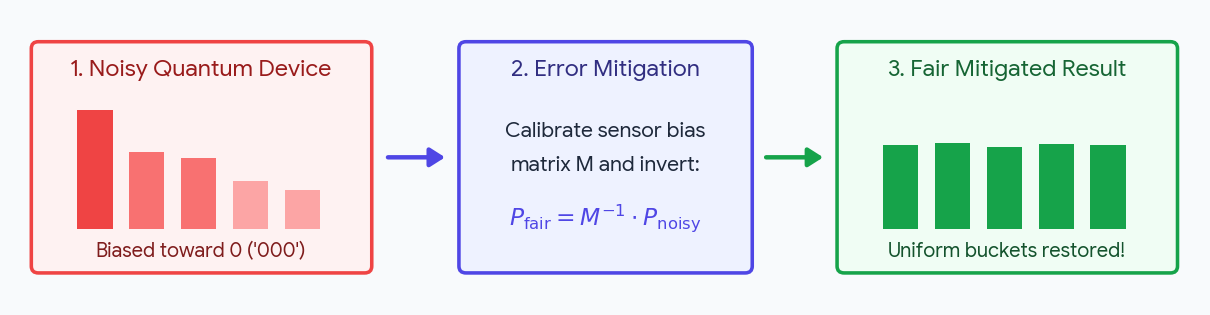

Let's simulate a noisy 3-qubit device using `NoiseModel` and test two ways to restore fairness:
1. **Readout Calibration Matrix ($M^-1$):** Measure all 8 basis states (`000` through `111`) to characterize how often the hardware flips `1` to `0`, then multiply our noisy distribution by $M^-1$.
2. **Von Neumann Debiasing (for single-bit streams):** Look at pairs of raw bits—turn `01` $\rightarrow$ `0`, turn `10` $\rightarrow$ `1`, and discard `00` and `11`. Since $P(0)P(1) = P(1)P(0)$, the output is guaranteed to be an exact 50/50 coin flip!

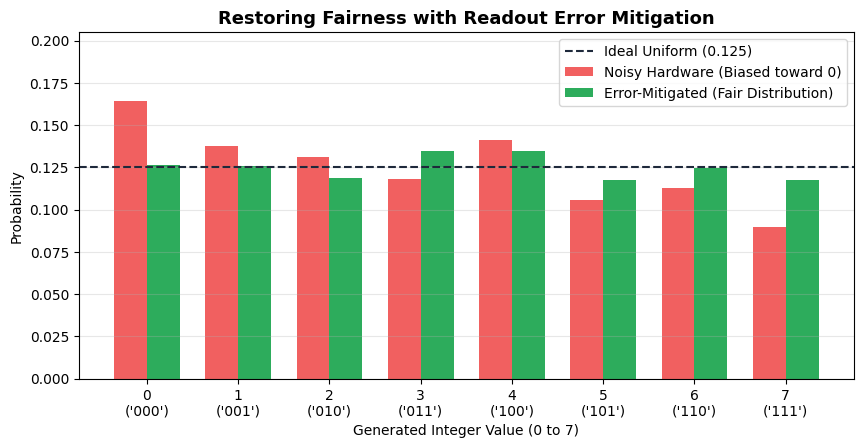

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error

# 1. Build a noisy simulator where |1> decays to |0> 12% of the time during readout
noise_model = NoiseModel()
readout_err = ReadoutError([[0.97, 0.03],
                            [0.12, 0.88]])
noise_model.add_all_qubit_readout_error(readout_err)
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 1), ["h"])

noisy_backend = AerSimulator(noise_model=noise_model)

# 2. Rebuild the 3-qubit uniform Hadamard circuit and run on noisy hardware
n = 3
q = QuantumRegister(n)
c = ClassicalRegister(n)
uniform_circ = QuantumCircuit(q, c)
for j in range(n):
    uniform_circ.h(q[j])
uniform_circ.measure(q, c)

shots = 8192
noisy_counts = noisy_backend.run(uniform_circ, shots=shots).result().get_counts()

# 3. Build the 8x8 Readout Calibration Matrix M
n_states = 2**n
cal_circuits = []
for state_idx in range(n_states):
    qc_cal = QuantumCircuit(n, n)
    bit_str = format(state_idx, f"0{n}b")
    for qubit_idx, bit in enumerate(reversed(bit_str)):
        if bit == "1":
            qc_cal.x(qubit_idx)
    qc_cal.measure(range(n), range(n))
    cal_circuits.append(qc_cal)

cal_results = noisy_backend.run(cal_circuits, shots=shots).result()

M = np.zeros((n_states, n_states))
for prep_idx in range(n_states):
    counts_cal = cal_results.get_counts(prep_idx)
    for meas_idx in range(n_states):
        M[meas_idx, prep_idx] = counts_cal.get(format(meas_idx, f"0{n}b"), 0) / shots

# 4. Apply M^-1 to remove readout bias
noisy_probs = np.array([noisy_counts.get(format(i, f"0{n}b"), 0) / shots for i in range(n_states)])
mitigated_probs = np.clip(np.linalg.inv(M) @ noisy_probs, 0, 1)
mitigated_probs /= np.sum(mitigated_probs)

# 5. Compare Noisy vs. Mitigated distributions
x = np.arange(n_states)
width = 0.36

plt.figure(figsize=(10, 4.5))
plt.bar(x - width/2, noisy_probs, width, label="Noisy Hardware (Biased toward 0)", color="#ef4444", alpha=0.85)
plt.bar(x + width/2, mitigated_probs, width, label="Error-Mitigated (Fair Distribution)", color="#16a34a", alpha=0.9)
plt.axhline(1 / n_states, color="#1e293b", linestyle="--", linewidth=1.5, label="Ideal Uniform (0.125)")
plt.title("Restoring Fairness with Readout Error Mitigation", fontsize=13, fontweight="bold")
plt.xlabel("Generated Integer Value (0 to 7)")
plt.ylabel("Probability")
plt.xticks(x, [f"{i}\n('{format(i, '03b')}')" for i in x])
plt.ylim(0, max(noisy_probs) * 1.25)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
# Post-processing alternative for 1-qubit bitstreams: Von Neumann Debiasing
def von_neumann_debias(raw_bits):
    unbiased = []
    for i in range(0, len(raw_bits) - 1, 2):
        pair = raw_bits[i] + raw_bits[i + 1]
        if pair == "01":
            unbiased.append("0")
        elif pair == "10":
            unbiased.append("1")
        # '00' and '11' pairs are discarded
    return unbiased

q1 = QuantumRegister(1)
c1 = ClassicalRegister(1)
coin_circ = QuantumCircuit(q1, c1)
coin_circ.h(q1)
coin_circ.measure(q1, c1)

raw_stream = noisy_backend.run(coin_circ, shots=4000, memory=True).result().get_memory()
fair_stream = von_neumann_debias(raw_stream)

print(f"Noisy 1-qubit stream  -> 0s: {raw_stream.count('0')/len(raw_stream):.1%}, 1s: {raw_stream.count('1')/len(raw_stream):.1%}")
print(f"Von Neumann debiased  -> 0s: {fair_stream.count('0')/len(fair_stream):.1%}, 1s: {fair_stream.count('1')/len(fair_stream):.1%} ({len(fair_stream)} bits kept)")

Noisy 1-qubit stream  -> 0s: 53.8%, 1s: 46.2%
Von Neumann debiased  -> 0s: 47.1%, 1s: 52.9% (990 bits kept)
